# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Josh SOUSSAN  Student ID: B00821791
2. Full name: Edouard SOUIED  Student ID: B00825107
3. Full name: Raphaël HAZAN  Student ID: B00820995
4. Full name: Nicolas SALAPETE  Student ID: B00821820

**Project role (consultant / data scientist / risk analyst):** Risk analyst
**Key quantity (one sentence, with unit):** The carbon slope premium: extra 5-10y CDS slope (s10y − s5y) of a carbon-intensive issuer vs. a financially identical low-carbon peer, implied by our Merton + carbon drain model at each year's EUA price, in **basis points**.
**Repo URL:** https://github.com/joshsssn/Research-and-emerging-topics-lab-5

## Setup (given)

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [20]:
# --- project model (paper, eq. 1-4) ---
LEV, SIG, R_F, REC = 2.5, 0.26, 0.03, 0.40   # V0/D, asset vol, rate, recovery
K_HIGH, K_LOW = 0.01 / (80 * 0.6), 0.0003 / (80 * 0.6)  # E/V, calibrated on Table 1 (P=80, phi=0.4)

def spread(T, d0, g):
    # Merton spread (bp) with drain d0*exp(g t)
    lam = d0 * (np.exp(g * T) - 1) / (g * T)  # avg drain over [0,T]
    dd = (np.log(LEV) + (R_F - lam - SIG**2 / 2) * T) / (SIG * np.sqrt(T))
    return -np.log(1 - (1 - REC) * stats.norm.cdf(-dd)) / T * 1e4

def slope_premium(price, phi, g=0.075):
    # (s10-s5)_high - (s10-s5)_low, in bp; vectorised
    price, phi, g = np.broadcast_arrays(np.asarray(price, float), np.asarray(phi, float), np.asarray(g, float))
    out = 0.0
    for k, sgn in [(K_HIGH, 1), (K_LOW, -1)]:
        d0 = price * k * (1 - phi)
        out = out + sgn * (spread(10, d0, g) - spread(5, d0, g))
    return out

# sanity check vs Table 1 (high firm: 92.0 / 118.9 bp)
print("check 5y/10y high:", spread(np.array([5., 10.]), 0.01, 0.075).round(1))

# EUA annual average prices, EUR/t
# 2013, 2017-19, 2021-24: ETC CM Report 2025/06 (EEA, from EEX/ICE); 2020: EEA (~25)
# 2008-12, 2014-16: approx. from secondary-market history, not checked against an official table
eua = pd.Series({2008: 22.0, 2009: 13.1, 2010: 14.3, 2011: 13.0, 2012: 7.4, 2013: 4.33,
                 2014: 6.0, 2015: 7.7, 2016: 5.3, 2017: 5.76, 2018: 15.50, 2019: 24.72,
                 2020: 24.8, 2021: 54.15, 2022: 80.18, 2023: 83.60, 2024: 64.76})

if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    series = pd.DataFrame({"year": eua.index.astype(int),
                           "value": slope_premium(eua.values, 0.4)})
    NAME, UNIT = "Carbon slope premium (s10y-s5y, high vs low carbon)", "bp"
series.tail()

check 5y/10y high: [ 92.2 119.4]


,year,value
12,2020,3.48
13,2021,8.00
14,2022,12.40
15,2023,13.00
16,2024,9.75


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

It's the extra 5-10y CDS slope our model gives a carbon-heavy firm vs. an identical clean peer, at each year's EUA price. Decision: should a credit desk price/hedge transition risk on the 10y tenor instead of the usual 5y point. Uncertainty: carbon price path (**S**), pass-through φ, unobservable (**E**), model form, smooth drift vs. regulatory jumps (**E**), year-to-year EUA noise (**A**), noisy/interpolated 10y quotes (**A**).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [21]:
def fit_predict(train, horizon, model="linear", level=0.90):
    y = train["value"].to_numpy(float)
    if model == "loglinear":
        assert (y > 0).all(); y = np.log(y)
    yr = train["year"].to_numpy(float); tbar = yr.mean()
    X = np.column_stack([np.ones_like(yr), yr - tbar])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    n, p = X.shape
    s2 = ((y - X @ beta) ** 2).sum() / (n - p)
    fy = np.arange(yr.max() + 1, yr.max() + 1 + horizon)
    X0 = np.column_stack([np.ones_like(fy), fy - tbar])
    m = X0 @ beta
    lev = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)  # x0'(X'X)^-1 x0
    half = stats.t.ppf(0.5 + level / 2, n - p) * np.sqrt(s2 * (1 + lev))
    lo, hi = m - half, m + half
    if model == "loglinear":
        m, lo, hi = np.exp(m), np.exp(lo), np.exp(hi)
    return pd.DataFrame({"year": fy.astype(int), "mean": m, "lo": lo, "hi": hi})

H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = pd.concat([fit_predict(train, H, m).assign(model=m) for m in ["linear", "loglinear"]])
backtest = backtest.merge(test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = backtest.actual.between(backtest.lo, backtest.hi)
backtest

,year,mean,lo,hi,model,actual,inside
0,2020,1.46,-0.65,3.57,linear,3.48,True
1,2020,1.14,0.31,4.23,loglinear,3.48,True
2,2021,1.44,-0.74,3.63,linear,8.00,False
3,2021,1.11,0.29,4.31,loglinear,8.00,False
4,2022,1.42,-0.84,3.69,linear,12.40,False
5,2022,1.08,0.27,4.41,loglinear,12.40,False
6,2023,1.40,-0.95,3.75,linear,13.00,False
7,2023,1.05,0.24,4.53,loglinear,13.00,False
8,2024,1.38,-1.07,3.83,linear,9.75,False
9,2024,1.02,0.22,4.68,loglinear,9.75,False


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

In [22]:
print(backtest.groupby("model").inside.sum().rename("inside (of 5)"))
# P(X >= k) misses for X ~ Bin(5, 0.1)
pd.DataFrame({"k": range(6), "P(X>=k)": [stats.binom.sf(k - 1, 5, 0.1) for k in range(6)]})

model
linear       1
loglinear    1
Name: inside (of 5), dtype: int64


,k,P(X>=k)
0,0,1.00
1,1,0.41
2,2,0.08
3,3,0.01
4,4,0.00
5,5,0.00


**Your answer (Q2):**

(a) Linear: **1/5** inside. Log-linear: **1/5** inside. Both catch 2020, then miss 2021-2024 (all above the band).
(b) P(X ≥ 2) = 0.08 and P(X ≥ 3) = 0.01, so 2+ misses already makes a 90% band doubtful; 4 misses (P ≈ 0.0005) rejects it. The rolling test agrees: coverage 0-43% instead of 90%.
(c) Neither, a time trend can't see the 2018-2022 EUA regime change (MSR reform, Fit for 55). The two models are close, so the problem isn't the functional form, it's using a trend at all. We drop trends and forecast from the inputs (Part C).

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [23]:
rows = []
for cut in range(10, len(series)):
    tr = series.iloc[:cut]
    for m in ["linear", "loglinear"]:
        pr = fit_predict(tr, 3, m).merge(series, on="year")  # drops years after 2024
        for h, r in enumerate(pr.itertuples(), 1):
            rows.append((m, h, r.lo <= r.value <= r.hi))
roll = pd.DataFrame(rows, columns=["model", "h", "inside"])
roll.groupby(["model", "h"]).inside.agg(["mean", "size"]).rename(columns={"mean": "coverage", "size": "n"})

coverage  n
model     h             
linear    1      0.29  7
          2      0.17  6
          3      0.00  5
loglinear 1      0.43  7
          2      0.17  6
          3      0.20  5

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [24]:
N = 5_000
TARGET = 2030
# P_2030 ~ lognormal, median 130 EUR/t, log-sd 0.35 (analyst forecasts spread ~70-230)
# phi ~ Uniform(0, 0.8): no reliable estimate, range from our paper (sec. 4.4)
P_MED, P_SD = 130, 0.35

def draw_inputs(n, p_med=P_MED, p_sd=P_SD):
    return p_med * np.exp(rng.normal(0, p_sd, n)), rng.uniform(0, 0.8, n)

def compute_quantity(price, phi, g=0.075):
    return slope_premium(price, phi, g)

def summ(x):
    q5, q50, q95 = np.percentile(x, [5, 50, 95])
    return pd.Series({"median": q50, "lo90": q5, "hi90": q95, "width": q95 - q5})

price, phi = draw_inputs(N)
base = compute_quantity(price, phi)

# one-at-a-time: fix one input at its median
sens = pd.DataFrame({
    "all random": summ(base),
    "price fixed": summ(compute_quantity(np.median(price), phi)),
    "phi fixed": summ(compute_quantity(price, np.median(phi))),
}).T
sens["rel_halfwidth"] = sens.width / 2 / sens["median"]
sens

,median,lo90,hi90,width,rel_halfwidth
all random,20.46,6.55,56.71,50.16,1.23
price fixed,21.58,7.58,39.27,31.69,0.73
phi fixed,21.58,10.89,43.93,33.04,0.77


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) 2030 slope premium: median **20.5 bp**, 90% interval **[6.6, 56.7] bp**.
(b) Fixing the **carbon price** shrinks it most (rel. half-width 1.23 → 0.73), φ is a close second (→ 0.77). The 2030 price is mostly **aleatoric/scenario** (market + policy outcome), φ is **epistemic** (fixed, just unknown).
(c) One more week: sector pass-through estimates (cement/steel margins around EUA shocks, existing pass-through studies) to narrow φ. The price part of the range stays whatever we do.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [25]:
# NGFS-style: shift P_2030 median and post-2030 growth g
SCEN = {
    "Current policies": dict(p_med=85, g=0.03),
    "Delayed transition": dict(p_med=100, g=0.12),
    "Net Zero 2050 (orderly)": dict(p_med=170, g=0.075),
}
draws = {s: (*draw_inputs(N, c["p_med"]), c["g"]) for s, c in SCEN.items()}
scen = pd.DataFrame({s: summ(compute_quantity(pr, ph, g)) for s, (pr, ph, g) in draws.items()}).T
gap = scen["median"].max() - scen["median"].min()
print(f"largest median gap: {gap:.1f} bp | width within scenarios: {scen.width.min():.1f}-{scen.width.max():.1f} bp")
scen

largest median gap: 21.1 bp | width within scenarios: 17.1-75.2 bp


,median,lo90,hi90,width
Current policies,7.53,2.56,19.62,17.06
Delayed transition,24.51,7.94,69.65,61.71
Net Zero 2050 (orderly),28.66,8.38,83.61,75.23


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

Largest median gap: **21.1 bp** (Net Zero 28.7 vs Current policies 7.5). Width inside one scenario: **17 to 75 bp**, so the within-scenario band is bigger than the scenario gap (except under current policies). Bands overlap a lot, so one pooled fan chart would hide that the scenario still shifts the center. We show **one band per scenario**, and say clearly they overlap.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [26]:
# your code here (optional)

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

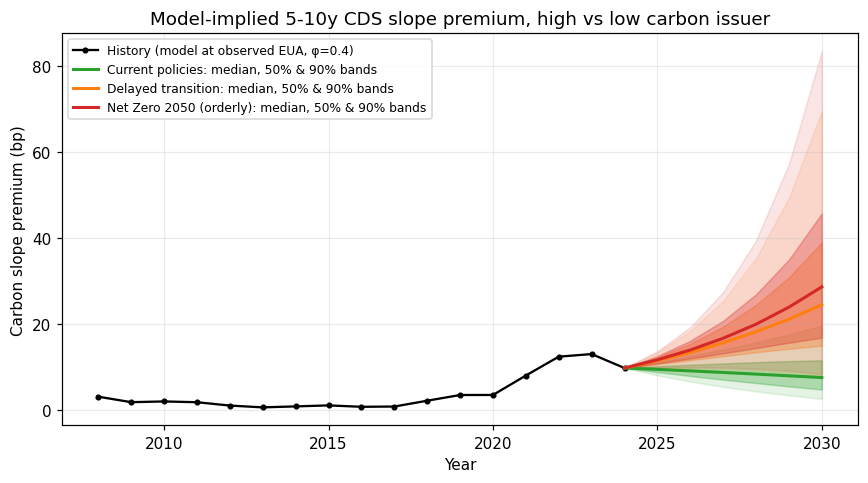

In [27]:
yrs = np.arange(2024, TARGET + 1)
p0 = eua[2024]
cols = {"Current policies": "tab:green", "Delayed transition": "tab:orange", "Net Zero 2050 (orderly)": "tab:red"}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(series.year, series.value, "k-o", ms=3, label="History (model at observed EUA, φ=0.4)")
w = (yrs - 2024) / (TARGET - 2024)
for s, (pr, ph, g) in draws.items():
    # widen from today's value (phi=0.4, g=7.5%) to the 2030 draws
    W = w[:, None]
    paths = p0 ** (1 - W) * pr[None, :] ** W          # log-interp price
    ph_t = 0.4 * (1 - W) + ph[None, :] * W
    g_t = 0.075 * (1 - W) + g * W
    q = np.percentile(compute_quantity(paths, ph_t, g_t), [5, 25, 50, 75, 95], axis=1)
    c = cols[s]
    ax.fill_between(yrs, q[0], q[4], color=c, alpha=0.12)
    ax.fill_between(yrs, q[1], q[3], color=c, alpha=0.30)
    ax.plot(yrs, q[2], color=c, lw=2, label=f"{s}: median, 50% & 90% bands")
ax.set_xlabel("Year"); ax.set_ylabel("Carbon slope premium (bp)")
ax.set_title("Model-implied 5-10y CDS slope premium, high vs low carbon issuer")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("fig_uncertainty.png", dpi=200)
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

Under an NGFS-style Net Zero 2050 path, our Merton + carbon drain model gives a 2030 carbon slope premium (5-10y CDS slope, high vs low carbon issuer) of about 29 bp (90% interval 8-84 bp); under our baseline price assumption it's 20.5 bp [6.6, 56.7]. A simple time trend failed the back-test: only 1 of 5 held-out years (2020-2024) fell inside its 90% band, so we forecast from inputs instead. The range is driven mostly by the 2030 EUA price, with unobserved pass-through close behind. The largest scenario gap is 21 bp (Net Zero vs Current policies). It is *likely* that the premium grows by 2030 outside current policies. Limitation: a smooth price drift cannot capture regulatory jumps, which could flip the maturity signature (Blasberg et al., 2024).

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is* how a credit desk measures transition risk: it should stress the 10y tenor under each scenario instead of reading one 5y spread, since the long end is where the carbon signal (and its uncertainty) sits."